# In this notebook an ANN will be created to estimate the RUL of Batteries
- The work is based on [this paper](https://arxiv.org/pdf/2305.10298)
- The dataset used is [NASA Battery dataset](https://labinfo.ing.he-arc.ch/gitlab/ticc/16TICc19/nasa-battery-dataset/-/tree/614f3518915079a5182655cadc3492973ac90d6c/data/BatteryAgingARC-FY08Q4)

## Step 0: Environment configuration

In [1]:
#%pip instal numpy; pandas; scipy; matplotlib; seaborn; scikit-learn; keras; tensorflow_cpu; kagglehub

## Step 1: Data collection
### Step 1.1: Data understanding

Generic Dataset Informations¶
Repeated charge and discharge cycles result in accelerated aging of the batteries while impedance measurements provide insight into the internal battery parameters that change as aging progresses.

- Charge profile:
    - The charge profile for all battery tests seems to be identifical.
    - Charging was carried out in a constant current (CC) mode at 1.5A until the battery voltage reached 4.2V and then continued in a constant voltage (CV) mode until the charge current dropped to 20mA.
- Discharge:
    - Discharge profiles were different from battery to battery.
    - Discharge was carried out at a constant current (CC) level of 1-4 A until the battery voltage fell to values such 2.7V, 2.5V, 2.2V and 2.5V.
- Impedance:
    - Impedance measurement was carried out through an electrochemical impedance spectroscopy (EIS) frequency sweep from 0.1Hz to 5kHz.

The experiments were stopped when the batteries reached a given end-of-life (EOL) criteria: for example 30% fade in rated capacity (from 2Ahr to 1.4Ahr). Other stopping criteria were used such as 20% fade in rated capacity. Note that for batteries 49,50,51,52, the experiments were not stop due to battery EOL but because the software has crashed.

Structure of .mat files
- dictionary (loaded mat file)
    - dictionary (e.g. B0005)
        - list (cycle) -> one test per element in the list
            - element of the list (dict) all data for one test of that battery
                - type: operation type, can be charge, discharge or impedance
                - ambient_temperature: ambient temperature (degree C)
                - time: the date and time of the start of the cycle, in MATLAB date vector format
                - data (dict): data structure containing the measurements
                    - data fields with key being measured variable, values the actual records (see below)

| Charge fields | Discharge fields | Impedance fields |
|---|---|---|
| Voltage_measured: Battery terminal voltage (Volts) | Voltage_measured: Battery terminal voltage (Volts) | Frequency: Frequency of impedance measurement (Hz) |
| Current_measured: Battery output current (Amps) | Current_measured: Battery output current (Amps) | Impedance: Battery internal impedance (Ohms) |
| Temperature_measured: Battery temperature (degree C) | Temperature_measured: Battery temperature (degree C) | Real_impedance: Real part of impedance (Ohms) |
| Current_charge: Current measured at charger (Amps) | Current_discharge: Current measured at load (Amps) | Imag_impedance: Imaginary part of impedance (Ohms) |
| Voltage_charge: Voltage measured at charger (Volts) | Voltage_discharge: Voltage measured at load (Volts) | Phase_angle: Phase angle of impedance (degrees) |
| Time: Time vector for the cycle (secs) | Time: Time vector for the cycle (secs) | Time: Time vector for the impedance spectrum (secs) |

### Step 1.2 File conversion from .mat to .csv*
*Firstly the notebook will load data from kaggle where data is already transformed into csv

The csv files will be imported and processed to get data for battery B0005

Helper function to print first x cycles of each type

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

def print_df(metadata, cycle_type, cycle_nr):
    fig, axes = plt.subplots(1, cycle_nr, figsize=(6*cycle_nr, 5))

    files = metadata.loc[metadata['type'] == cycle_type, 'filename']
    nr = 0
    for file in files:
        path = 'data\\cleaned_dataset\\data\\' + file
        df_temp = pd.read_csv(path)

        ylim = 5
        if cycle_type == 'charge':
            xlim = 10000
        else: 
            xlim = 4000

        ax = axes[nr]
        sns.lineplot(df_temp, x='Time', y='Voltage_measured', label='Voltage', color='r', ax=ax)
        sns.lineplot(df_temp, x='Time', y='Current_measured', label='Current', color='b', ax=ax)
        ax.set_title(f'{cycle_type.title()} cycle {nr + 1}')
        ax.set_xlabel('Time [s]')
        ax.set_ylabel('Voltage [V] / Current [A]')
        ax.set_xlim(right = xlim)
        ax.set_ylim((-ylim, ylim))
        ax.legend()
        
        nr += 1
        if nr > cycle_nr-1:
            break


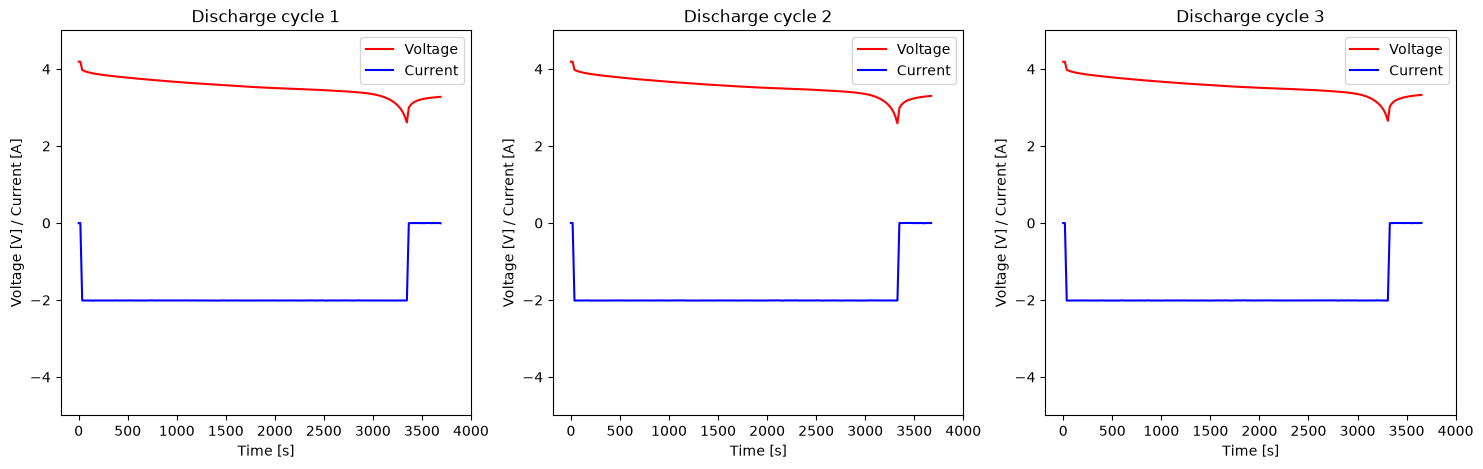

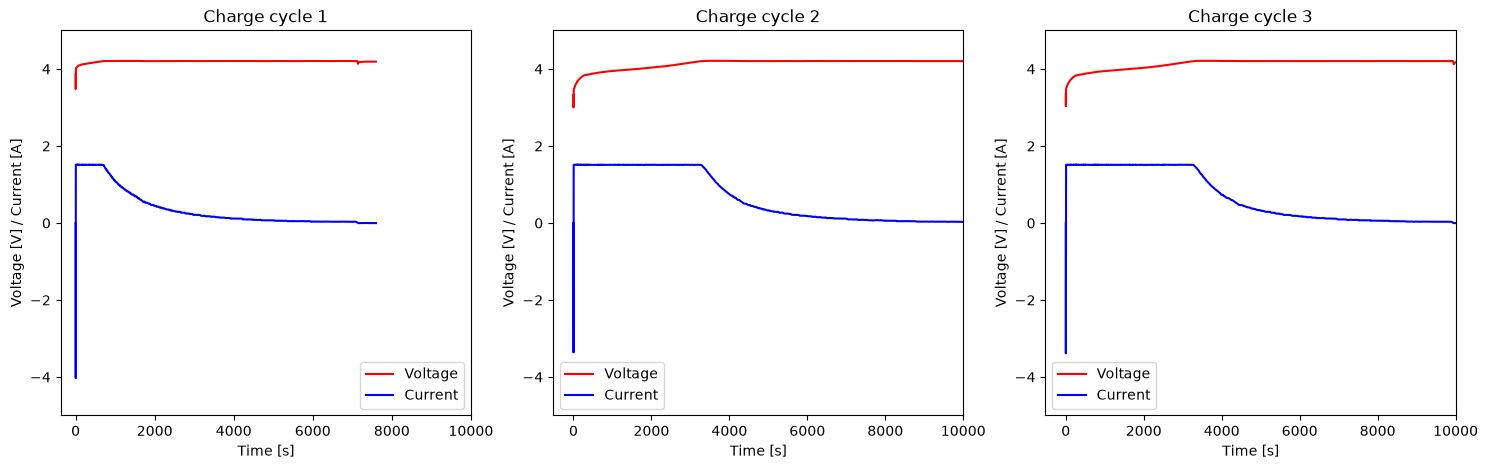

In [28]:
import pandas as pd
import scipy.io
import kagglehub

# Download latest version
path = kagglehub.dataset_download(handle="patrickfleith/nasa-battery-dataset", output_dir='data')

metadata = pd.read_csv('data\\cleaned_dataset\\metadata.csv')
# display(metadata.head())

b0005_metadata = metadata[metadata['battery_id'] == 'B0005']
# b0005_metadata.info()

b0005_files = b0005_metadata['filename']

b0005_df = pd.DataFrame()

#    b0005_df = pd.concat([b0005_df, df_temp], ignore_index=True)

print_df(b0005_metadata, cycle_type='discharge', cycle_nr=3)
print_df(b0005_metadata, cycle_type='charge', cycle_nr=3)

One row statistics(Features) that will be calculated for the charge/discharge cycles

In [49]:
#Compute one rows statistics of the (dis)charge cycles
import numpy as np


def create_features(metadata, cycle_type):
    
    b0005_files = metadata.loc[metadata['type'] == cycle_type, 'filename']
    nr = 0
    for file in b0005_files:
        path = 'data\\cleaned_dataset\\data\\' + file
        print(file)
        df = pd.read_csv(path)
        df['Current_charge'] = df['Current_charge'].clip(lower=0)
        df["Current_diff"] = df["Current_charge"].round(2).diff()
        df.loc[0, 'Current_diff'] = 0
        cutoff_idx = (df['Current_diff']>=0).idxmin()
        print(cutoff_idx)
        time_cc = df['Time'].iloc[cutoff_idx]
        time_cv = df['Time'].iloc[-1] - time_cc

        print(time_cc)
        print(time_cv)

        start_voltage = df['Voltage_measured'].min()
        current = df['Current_charge'].max()
        nr+=1
        if nr >= 1:
            break

    df.head()


create_features(b0005_metadata, 'charge')    

05121.csv
193
682.75
6915.125


In [4]:
b0005_df.head()

,Voltage_measured,Current_measured,Temperature_measured,Current_charge,Voltage_charge,Time,Current_load,Voltage_load,Sense_current,Battery_current,Current_ratio,Battery_impedance,Rectified_Impedance
0,3.873017,-0.001201,24.655358,0.000,0.003,0.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,3.479394,-4.030268,24.666480,-4.036,1.570,2.532,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.000588,1.512731,24.675394,1.500,4.726,5.500,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,4.012395,1.509063,24.693865,1.500,4.742,8.344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4.019708,1.511318,24.705069,1.500,4.753,11.125,NaN,NaN,NaN,NaN,NaN,NaN,NaN
